# 05 - Churn, hypothesis tests and early-warning rule

**Goal:** define churn from the data, test the remaining "whys" statistically, and back-test a simple early-warning rule.

**Input:** `data/processed/transactions_clean.csv`
**Output:** `data/processed/churn_rule_backtest.csv`, `data/processed/at_risk_customers.csv`

## Design: a time-split back-test
- **Cutoff:** 30 Jun 2011. Everything a customer did up to the cutoff is the *history*.
- **Base:** tracked customers with at least one purchase in the 12 months before the cutoff.
- **Churned** = no purchase between 1 Jul and 9 Dec 2011 (the *holdout*, 161 days, which includes the Sep-Nov peak).
- Features use history only, so nothing leaks from the holdout.

**5 Whys covered here**
- #3: do purchase gaps lengthen before customers churn?
- #4: are cancellations linked to churn?
- #5: can a simple rule flag at-risk customers early enough to act?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

ROOT = Path.cwd().parent  # notebook runs from notebooks/
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.2f}".format)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150)

In [2]:
from scipy import stats
import statsmodels.api as sm

In [3]:
df = pd.read_csv(
    PROCESSED_DIR / "transactions_clean.csv",
    parse_dates=["invoice_date", "invoice_month", "first_purchase_month"],
    dtype={"invoice": str, "stock_code": str, "customer_id": "Int64"},
)
sales = df[~df.is_cancellation]
cancels = df[df.is_cancellation]
tracked = sales[sales.has_customer]  # customer-level analysis only

LAST_FULL_MONTH = pd.Timestamp("2011-11-01")  # data ends 9 Dec 2011 (partial month)

## 1. Build history, base and churn label

In [4]:
HOLDOUT_END = df.invoice_date.max()
CUTOFF = pd.Timestamp("2011-06-30 23:59:59")
SNAPSHOT = HOLDOUT_END.normalize() + pd.Timedelta(days=1)  # "today" for the live at-risk list

def build_features(cutoff):
    # Per-customer features using only data up to `cutoff`, for customers active in the 12 months before it.
    window_start = cutoff - pd.Timedelta(days=365)
    hist = tracked[tracked.invoice_date <= cutoff]                      # sales only
    hist_all = df[df.has_customer & (df.invoice_date <= cutoff)]       # sales and cancellations
    base_ids = hist.loc[hist.invoice_date > window_start, "customer_id"].unique()

    # Order *days* (several invoices on one day count once), so gaps are whole days >= 1
    days = (
        hist.assign(day=hist.invoice_date.dt.normalize())
        .drop_duplicates(["customer_id", "day"])[["customer_id", "day"]]
        .sort_values(["customer_id", "day"])
    )
    days["gap"] = days.groupby("customer_id").day.diff().dt.days
    g = days.groupby("customer_id")

    feat = pd.DataFrame({
        "last_purchase": g.day.max(),
        "order_days": g.day.size(),
        "gap_sum": g.gap.sum(),
        "last_gap": g.gap.last(),  # most recent completed gap
    })
    feat["n_gaps"] = feat.order_days - 1
    feat["avg_gap"] = feat.gap_sum / feat.n_gaps.where(feat.n_gaps > 0)
    feat["earlier_avg_gap"] = (feat.gap_sum - feat.last_gap) / (feat.n_gaps - 1).where(feat.n_gaps > 1)
    feat["recency"] = (cutoff.normalize() - feat.last_purchase).dt.days

    in_window = hist_all[hist_all.invoice_date > window_start]
    feat["trailing_rev"] = in_window.groupby("customer_id").line_total.sum()   # net of cancellations
    feat["invoices"] = hist.groupby("customer_id").invoice.nunique()

    sales_hist = hist.groupby("customer_id").line_total.sum()
    cancel_hist = -hist_all[hist_all.is_cancellation].groupby("customer_id").line_total.sum()
    feat["cancel_rate"] = (cancel_hist / sales_hist).reindex(feat.index).fillna(0).clip(0, 1)
    feat["uk"] = (hist.groupby("customer_id").country.first() == "United Kingdom").astype(int)

    feat = feat.loc[feat.index.isin(base_ids)].copy()
    feat["trailing_rev"] = feat.trailing_rev.fillna(0).round(2)
    feat["overdue_ratio"] = feat.recency / feat.avg_gap.where(feat.avg_gap > 0)
    return feat

feat = build_features(CUTOFF)
future_ids = set(tracked.loc[tracked.invoice_date > CUTOFF, "customer_id"])
feat["churned"] = (~feat.index.isin(future_ids)).astype(int)

print(f"base customers (active in the 12 months to the cutoff): {len(feat):,}")
print(f"holdout length: {(HOLDOUT_END - CUTOFF).days} days")
print(f"churn rate in holdout: {feat.churned.mean():.1%}")
feat.head()

base customers (active in the 12 months to the cutoff): 4,326
holdout length: 161 days
churn rate in holdout: 43.9%


,last_purchase,order_days,gap_sum,last_gap,n_gaps,avg_gap,earlier_avg_gap,recency,trailing_rev,invoices,cancel_rate,uk,overdue_ratio,churned
customer_id,,,,,,,,,,,,,,
12346,2011-01-18,8,400.00,204.00,7,57.14,32.67,163,-5.50,12,1.00,1,2.85,1
12347,2011-06-09,5,221.00,63.00,4,55.25,52.67,21,"2,817.48",5,0.00,0,0.38,0
12348,2011-04-05,4,190.00,70.00,3,63.33,60.00,86,"1,709.40",4,0.00,0,1.36,0
12349,2010-10-28,3,182.00,163.00,2,91.00,19.00,245,"1,402.62",3,0.01,0,2.69,0
12350,2011-02-02,1,0.00,NaN,0,NaN,NaN,148,334.40,1,0.00,0,NaN,1


## 2. Churn by how long a customer has been silent

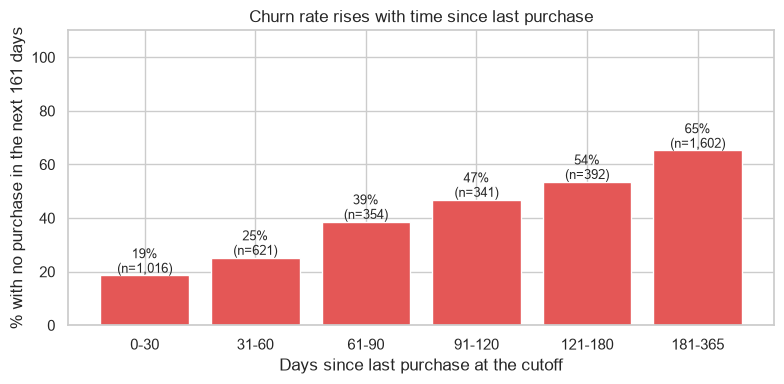

,customers,churn_rate,median_rev
recency,,,
0-30,1016,0.19,"1,544.32"
31-60,621,0.25,"1,119.13"
61-90,354,0.39,687.61
91-120,341,0.47,581.40
121-180,392,0.54,579.49
181-365,1602,0.65,350.36


In [5]:
bands = pd.cut(feat.recency, [-1, 30, 60, 90, 120, 180, 365], labels=["0-30", "31-60", "61-90", "91-120", "121-180", "181-365"])
by_band = feat.groupby(bands, observed=True).agg(customers=("churned", "size"), churn_rate=("churned", "mean"), median_rev=("trailing_rev", "median"))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_band.index.astype(str), by_band.churn_rate * 100, color="#E45756")
for x, (v, n) in enumerate(zip(by_band.churn_rate * 100, by_band.customers)):
    ax.text(x, v + 1, f"{v:.0f}%\n(n={n:,})", ha="center", fontsize=9)
ax.set_ylim(0, 110)
ax.set_xlabel("Days since last purchase at the cutoff")
ax.set_ylabel("% with no purchase in the next 161 days")
ax.set_title("Churn rate rises with time since last purchase")
save(fig, "05_churn_by_recency")
plt.show()
by_band

## 3. Hypothesis tests

All tests are two-sided Mann-Whitney U tests (the metrics are skewed, so medians and rank tests are safer than means and t-tests). The effect size is the probability that a random churned customer scores higher than a random retained one (0.5 = no difference).

In [6]:
def compare(metric, data=feat, label=None):
    a = data.loc[data.churned == 1, metric].dropna()
    b = data.loc[data.churned == 0, metric].dropna()
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    return {
        "metric": label or metric,
        "n_churned": len(a), "n_retained": len(b),
        "median_churned": a.median(), "median_retained": b.median(),
        "P(churned > retained)": u / (len(a) * len(b)),
        "p_value": p,
    }

# #3: do gaps lengthen before churn? Needs >= 4 order days (3 gaps) to compare the last gap with earlier ones.
feat["gap_growth"] = feat.last_gap / feat.earlier_avg_gap.where(feat.earlier_avg_gap > 0)
h3 = feat[feat.order_days >= 4]

tests = pd.DataFrame([
    compare("gap_growth", h3, "H3: last gap / earlier average gap (customers with 4+ order days)"),
    compare("overdue_ratio", feat[feat.order_days >= 3], "H3b: days silent / average gap (3+ order days)"),
    compare("cancel_rate", feat, "H4: cancelled value / sales value"),
    compare("trailing_rev", feat, "Value: trailing 12-month net sales"),
    compare("invoices", feat, "Frequency: invoices to date"),
])
tests

,metric,n_churned,n_retained,median_churned,median_retained,P(churned > retained),p_value
0,H3: last gap / earlier average gap (customers ...,448,1487,1.06,1.07,0.51,0.58
1,H3b: days silent / average gap (3+ order days),685,1772,1.66,0.71,0.65,0.00
2,H4: cancelled value / sales value,1898,2428,0.00,0.00,0.41,0.00
3,Value: trailing 12-month net sales,1898,2428,363.27,"1,089.99",0.24,0.00
4,Frequency: invoices to date,1898,2428,2.00,5.00,0.25,0.00


In [7]:
# H4 as a simple 2x2: any cancellation vs churn
feat["any_cancel"] = feat.cancel_rate > 0
table = pd.crosstab(feat.any_cancel, feat.churned)
chi2, p, _, _ = stats.chi2_contingency(table)
print(table.rename(index={False: "no cancellation", True: "has cancellation"}, columns={0: "retained", 1: "churned"}))
print(f"\nchurn rate: no cancellation {table.loc[False, 1] / table.loc[False].sum():.1%}, "
      f"with cancellation {table.loc[True, 1] / table.loc[True].sum():.1%} (chi-square p = {p:.3g})")

churned           retained  churned
any_cancel                         
no cancellation       1081     1280
has cancellation      1347      618

churn rate: no cancellation 54.2%, with cancellation 31.5% (chi-square p = 8.29e-51)


## 4. Multivariate view: logistic regression

Predictors are on a log2 scale, so each odds ratio is the change in the odds of churning for a **doubling** of that metric.

In [8]:
X = pd.DataFrame({
    "recency (days silent)": np.log2(1 + feat.recency),
    "invoices to date": np.log2(1 + feat.invoices),
    "trailing 12m net sales": np.log2(1 + feat.trailing_rev.clip(lower=0)),
    "cancel rate": feat.cancel_rate,
    "UK customer": feat.uk,
})
model = sm.Logit(feat.churned, sm.add_constant(X)).fit(disp=0)

summary = pd.DataFrame({
    "odds_ratio": np.exp(model.params),
    "ci_low": np.exp(model.conf_int()[0]),
    "ci_high": np.exp(model.conf_int()[1]),
    "p_value": model.pvalues,
}).drop(index="const")

pred = model.predict(sm.add_constant(X))
u, _ = stats.mannwhitneyu(pred[feat.churned == 1], pred[feat.churned == 0])
print(f"AUC = {u / ((feat.churned == 1).sum() * (feat.churned == 0).sum()):.3f}  |  pseudo R2 = {model.prsquared:.3f}")
summary

AUC = 0.786  |  pseudo R2 = 0.201


,odds_ratio,ci_low,ci_high,p_value
recency (days silent),1.34,1.28,1.40,0.00
invoices to date,0.60,0.54,0.67,0.00
trailing 12m net sales,0.75,0.71,0.80,0.00
cancel rate,1.33,0.54,3.29,0.54
UK customer,0.96,0.75,1.24,0.78


## 5. Back-test an early-warning rule

A rule must be simple enough for a sales team to run in a spreadsheet. Two families are tested on the same holdout:

1. **Fixed silence:** flag a customer after N days with no purchase.
2. **Relative silence:** flag after `m` times the customer's own average gap (needs 3+ order days).

Metrics: *precision* = share of flagged customers who truly churned, *recall* = share of all churners flagged, *lift* = precision / base churn rate, *revenue captured* = share of churners' trailing revenue that was flagged.

In [9]:
def evaluate(name, flag, data=feat):
    flagged = data[flag]
    churners = data[data.churned == 1]
    precision = flagged.churned.mean() if len(flagged) else np.nan
    return {
        "rule": name,
        "flagged": len(flagged),
        "precision": precision,
        "recall": flagged.churned.sum() / data.churned.sum(),
        "lift": precision / data.churned.mean(),
        "revenue_captured": flagged.loc[flagged.churned == 1, "trailing_rev"].sum() / churners.trailing_rev.sum(),
    }

rows = [evaluate(f"silent > {n} days", feat.recency > n) for n in (45, 60, 90, 120, 150, 180)]
eligible = feat[feat.order_days >= 3]
rows += [evaluate(f"silent > {m}x own avg gap (3+ orders)", eligible.overdue_ratio > m, eligible) for m in (1.5, 2, 3, 4)]
backtest = pd.DataFrame(rows)
backtest["f1"] = 2 * backtest.precision * backtest.recall / (backtest.precision + backtest.recall)
backtest

,rule,flagged,precision,recall,lift,revenue_captured,f1
0,silent > 45 days,2974,0.55,0.86,1.25,0.81,0.67
1,silent > 60 days,2689,0.58,0.82,1.32,0.74,0.68
2,silent > 90 days,2335,0.61,0.75,1.38,0.65,0.67
3,silent > 120 days,1994,0.63,0.66,1.43,0.54,0.64
4,silent > 150 days,1764,0.64,0.60,1.46,0.47,0.62
5,silent > 180 days,1602,0.65,0.55,1.49,0.42,0.60
6,silent > 1.5x own avg gap (3+ orders),845,0.43,0.53,1.55,0.52,0.48
7,silent > 2x own avg gap (3+ orders),650,0.46,0.44,1.66,0.44,0.45
8,silent > 3x own avg gap (3+ orders),398,0.53,0.31,1.89,0.35,0.39
9,silent > 4x own avg gap (3+ orders),279,0.56,0.23,2.02,0.29,0.33


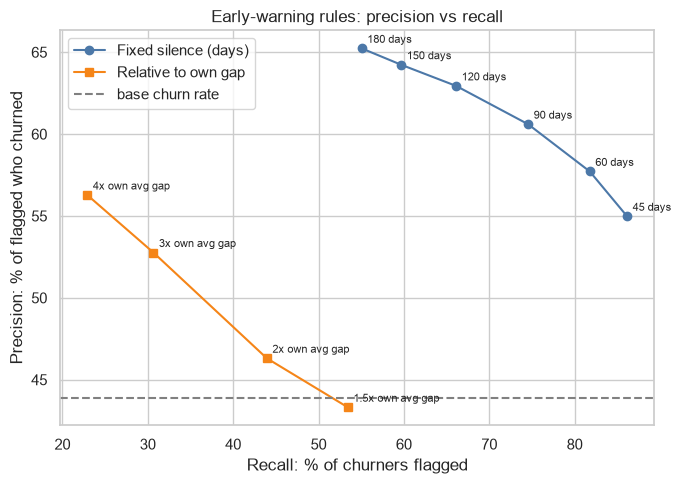

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
fixed = backtest[backtest.rule.str.startswith("silent > ") & backtest.rule.str.contains("days")]
rel = backtest[backtest.rule.str.contains("avg gap")]
ax.plot(fixed.recall * 100, fixed.precision * 100, "o-", label="Fixed silence (days)", color="#4C78A8")
ax.plot(rel.recall * 100, rel.precision * 100, "s-", label="Relative to own gap", color="#F58518")
for _, r in backtest.iterrows():
    ax.annotate(r.rule.split(" (")[0].replace("silent > ", ""), (r.recall * 100, r.precision * 100), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.axhline(feat.churned.mean() * 100, ls="--", color="grey", label="base churn rate")
ax.set_xlabel("Recall: % of churners flagged")
ax.set_ylabel("Precision: % of flagged who churned")
ax.set_title("Early-warning rules: precision vs recall")
ax.legend()
save(fig, "05_rule_precision_recall")
plt.show()

## 6. Apply the rule today

Chosen rules, based on the back-test:

- **Broad trigger:** no purchase for **90 days**. At the 30 Jun 2011 cutoff it catches 75% of churners and 65% of churner revenue, with 61% precision (at other cutoffs recall is 45-76%; see notebook 11). Longer thresholds lose recall quickly; shorter ones flag many customers who simply order seasonally.
- **Early trigger for repeat buyers:** silent for **more than 1.5x their own average gap** (3+ order days). Precision is 43% against a 28% base churn rate for this group, so it is a useful prioritisation signal, not a standalone churn flag.

Applied at the end of the data (10 Dec 2011) to customers active in the previous 12 months. Value at risk is trailing 12-month net sales; expected loss multiplies it by the back-test precision, because about 4 in 10 flagged customers came back anyway.

In [11]:
RULE_DAYS = 90
precision_90 = backtest.loc[backtest.rule == f"silent > {RULE_DAYS} days", "precision"].iloc[0]

now = build_features(SNAPSHOT)
now["flag_90d"] = now.recency > RULE_DAYS
now["flag_early"] = (now.order_days >= 3) & (now.overdue_ratio > 1.5)
now["value_quintile"] = pd.qcut(now.trailing_rev.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

at_risk = now[now.flag_90d & (now.trailing_rev > 0)]
print(f"active customers in the last 12 months: {len(now):,}")
print(f"flagged (silent > {RULE_DAYS} days): {len(at_risk):,} ({len(at_risk) / len(now):.0%})")
print(f"trailing 12m net sales of flagged customers: £{at_risk.trailing_rev.sum():,.0f} "
      f"({at_risk.trailing_rev.sum() / now.trailing_rev.sum():.0%} of all active customers' sales)")
print(f"expected loss at back-test precision ({precision_90:.0%}): £{at_risk.trailing_rev.sum() * precision_90:,.0f}")

tier = at_risk.groupby("value_quintile").agg(customers=("trailing_rev", "size"), trailing_rev=("trailing_rev", "sum"), median_silent_days=("recency", "median"))
tier.index.name = "value quintile (5 = highest)"
tier

active customers in the last 12 months: 4,264
flagged (silent > 90 days): 1,365 (32%)
trailing 12m net sales of flagged customers: £808,607 (10% of all active customers' sales)
expected loss at back-test precision (61%): £490,012


,customers,trailing_rev,median_silent_days
value quintile (5 = highest),,,
1,474,"68,383.70",233.00
2,389,"131,506.20",215.00
3,272,"174,551.80",173.00
4,170,"215,902.96",142.50
5,60,"218,262.44",140.00


In [12]:
priority = (
    at_risk[at_risk.value_quintile == 5]
    .sort_values("trailing_rev", ascending=False)
    [["recency", "avg_gap", "order_days", "trailing_rev", "flag_early"]]
    .rename(columns={"recency": "days_silent", "order_days": "order_days_total"})
)
print(f"top-value flagged customers: {len(priority):,} worth £{priority.trailing_rev.sum():,.0f} trailing 12m sales")
priority.head(10)

top-value flagged customers: 60 worth £218,262 trailing 12m sales


,days_silent,avg_gap,order_days_total,trailing_rev,flag_early
customer_id,,,,,
15749,236,97.00,2,"21,535.90",False
16180,101,43.40,11,"10,217.48",True
12590,212,NaN,1,"9,861.38",False
12980,158,29.00,21,"7,092.06",True
13093,276,10.95,43,"6,942.07",True
13027,114,31.94,19,"6,912.00",True
16553,164,33.53,16,"5,668.82",True
12688,114,NaN,1,"4,873.81",False
14016,162,53.90,11,"4,328.46",True


## 7. Save outputs

In [13]:
backtest.to_csv(PROCESSED_DIR / "churn_rule_backtest.csv", index=False)
by_band.reset_index(names="days_silent").astype({"days_silent": str}).to_csv(PROCESSED_DIR / "churn_by_recency.csv", index=False)

export = now.reset_index().assign(snapshot=SNAPSHOT.date())
export[["customer_id", "snapshot", "last_purchase", "recency", "order_days", "avg_gap", "overdue_ratio",
        "trailing_rev", "value_quintile", "flag_90d", "flag_early"]].to_csv(PROCESSED_DIR / "at_risk_customers.csv", index=False)
print(f"saved back-test table and {len(export):,} active customers with risk flags")

saved back-test table and 4,264 active customers with risk flags


## 8. Key takeaways

| Question | Result |
|---|---|
| Base churn | 43.9% of 4,326 customers active in the year to 30 Jun 2011 made no purchase in the next 161 days |
| Does silence predict churn? | Yes, strongly: churn rises from 19% (0-30 days silent) to 65% (181-365 days) |
| **#3 Do gaps lengthen before churn?** | **Refuted.** The last gap versus earlier gaps does not differ between churners and retained customers (p = 0.58). What matters is current silence, not a slowing trend |
| **#4 Do cancellations drive churn?** | **Refuted.** Customers with cancellations churn *less* (31.5% vs 54.2%) because they order more often. After controlling for frequency, value and recency, cancel rate is not significant (p = 0.54) |
| What does predict churn? | Days silent (odds x1.34 per doubling), fewer orders (x0.60 per doubling) and lower value (x0.75 per doubling). Model AUC 0.79 |
| **#5 Can a simple rule catch it?** | **At this cutoff, yes.** "Silent > 90 days" flags 54% of customers, catches 75% of churners and 65% of churner revenue. Across five cutoffs (notebook 11) precision is 61-76% but recall is 45-76% (only 45-49% at the two 2010 cutoffs), so the 75% figure is not general |

### Caveats
- One back-test window (Jul-Dec 2011) that includes the Q4 peak. Notebook 11 repeats the test at four other cutoffs; the rule stays useful, but recall changes a lot with the date. Seasonal buyers who skip a quarter are counted as churned only if they also miss Q4.
- Churn here means "no purchase in 161 days", not a confirmed loss. Some flagged customers return later.
- The relative-gap rule is evaluated on customers with 3+ order days, a different and lower-churn group, so its precision and recall are not directly comparable with the fixed-day rules.
- Trailing sales are descriptive, not a forecast.